# Phân loại cảm xúc câu trên SST-2 (GLUE) bằng BERT

> **Nguồn gốc & ghi công (credits)**
>
> - Bộ dữ liệu: **Stanford Sentiment Treebank** — Richard Socher và cộng sự (2013), *"Recursive Deep Models for Semantic
>   Compositionality Over a Sentiment Treebank"*, EMNLP 2013. Bản nhị phân **SST-2** được tải từ bộ **GLUE**
>   (Wang và cộng sự, 2019): [`nyu-mll/glue`](https://huggingface.co/datasets/nyu-mll/glue), cấu hình `sst2`.
> - Nhãn tập test: GLUE ẩn nhãn test (`-1`), nên nhãn gốc của SST được lấy từ
>   [`SetFit/sst2`](https://huggingface.co/datasets/SetFit/sst2) rồi ghép theo nội dung câu (mục 2.2).
> - Mô hình: **BERT** — Devlin và cộng sự (2019). Trọng số `bert-base-uncased` do Google phát hành (Apache 2.0).
> - Quy trình fine-tuning tham khảo [Hugging Face LLM Course — Chương 3](https://huggingface.co/learn/llm-course/chapter3) (Apache 2.0).
> - Thư viện: 🤗 Transformers, 🤗 Datasets, PyTorch, scikit-learn.

## 0. Tổng quan

**Bài toán**: cho một câu nhận xét phim tiếng Anh, dự đoán cảm xúc `negative` (0) hay `positive` (1).

**Mục tiêu**: fine-tune `bert-base-uncased`, đánh giá bằng accuracy, precision, recall, F1 và so sánh với baseline
**TF-IDF + Logistic Regression**.

### Hai đặc điểm của SST-2 quyết định cách thiết kế thí nghiệm

| Đặc điểm | Hệ quả |
|---|---|
| **Train là cụm từ, không phải câu**: 67.349 mẫu là các nút trong cây cú pháp của ~6.900 câu; validation và test là câu đầy đủ. | Không tách dev ngẫu nhiên từ train, vì các cụm từ của cùng một câu sẽ rơi vào cả hai phía và làm điểm dev lạc quan giả tạo. Validation chính thức được dùng làm dev. |
| **GLUE ẩn nhãn test** (toàn bộ là `-1`). | Nếu chỉ dùng GLUE thì validation vừa để chọn mô hình vừa để báo cáo, nên kết quả bị lạc quan. Vì vậy nhãn test gốc được khôi phục và tập test chỉ được dùng để báo cáo sau khi đã chốt mô hình. |

### Quy trình

| Tập | Số mẫu | Vai trò |
|---|---:|---|
| GLUE `train` | 67.349 | Huấn luyện cả hai mô hình |
| GLUE `validation` | 872 | Chọn siêu tham số của baseline và epoch của BERT; cũng là con số thường được báo cáo cho GLUE |
| GLUE `test` + nhãn gốc SST | 1.821 | Đánh giá cuối cùng, không dùng để chọn mô hình |

**Độ đo**: lớp dương là `positive`. Accuracy là độ đo chính vì hai tập đánh giá gần như cân bằng. Do tập test nhỏ, mọi kết quả chính đều
kèm **khoảng tin cậy bootstrap 95%** và so sánh hai mô hình bằng **kiểm định McNemar**.

## 1. Cài đặt và nạp thư viện

Phần BERT nên chạy trên GPU. Notebook tự chọn `cuda` → `mps` (Mac) → `cpu`. Có thể đặt `N_TRAIN` ở mục 5.1 để chạy thử nhanh.

In [1]:
%pip install -q "transformers>=4.40" "datasets>=2.18" torch "scikit-learn>=1.3" scipy pandas matplotlib

In [2]:
%matplotlib inline
import random
import re
import time
import unicodedata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats
import sklearn
import torch
import datasets
import huggingface_hub
import transformers
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from sklearn.pipeline import Pipeline
from torch.utils.data import DataLoader
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)

plt.style.use('ggplot')
datasets.disable_progress_bars()
huggingface_hub.utils.disable_progress_bars()
transformers.logging.set_verbosity_error()
transformers.logging.disable_progress_bar()

SEED = 42
LABEL_NAMES = ['negative', 'positive']


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)   # đồng thời đặt hạt giống cho cuda và mps


set_seed()
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():
    device = torch.device('mps')
else:
    device = torch.device('cpu')

print('thiết bị    :', device)
print('scikit-learn:', sklearn.__version__)
print('torch       :', torch.__version__)
print('transformers:', transformers.__version__)
print('datasets    :', datasets.__version__)

thiết bị    : cuda
scikit-learn: 1.6.1
torch       : 2.11.0+cu130
transformers: 5.22.0
datasets    : 4.8.5


## 2. Dữ liệu

### 2.1. Tải SST-2 từ GLUE

In [3]:
glue = load_dataset('nyu-mll/glue', 'sst2', cache_dir='data/glue_sst2')
train_df = glue['train'].to_pandas().rename(columns={'sentence': 'text'})
dev_df = glue['validation'].to_pandas().rename(columns={'sentence': 'text'})
test_df = glue['test'].to_pandas().rename(columns={'sentence': 'text'})

print(glue['train'].features['label'])
print('Nhãn trong GLUE test:', test_df['label'].value_counts().to_dict())
train_df.head()

ClassLabel(names=['negative', 'positive'])
Nhãn trong GLUE test: {-1: 1821}


,text,label,idx
0,hide new secretions from the parental units,0,0
1,"contains no wit , only labored gags",0,1
2,that loves its characters and communicates som...,1,2
3,remains utterly satisfied to remain the same t...,0,3
4,on the worst revenge-of-the-nerds clichés the ...,0,4


### 2.2. Khôi phục nhãn test

Toàn bộ nhãn trong GLUE `test` bằng `-1`. `SetFit/sst2` giữ nhãn gốc của SST nhưng thứ tự khác và kiểu ghi khác
(`-lrb-` thay cho `(`, `\/` thay cho `/`, có chữ có dấu). Vì vậy không ghép theo vị trí, mà ghép theo **khoá chuẩn hoá**:
bỏ dấu, viết thường, bỏ ký hiệu ngoặc và mọi ký tự không phải chữ hoặc số. Có đúng 4 câu test khác nhau do chính tả Anh–Mỹ
(*humour/humor*, *learnt/learned*, *favourite/favorite*, *favour/favor*), nên các cặp từ này cũng được quy về một dạng.

Việc ghép có hai điều kiện kiểm tra và sẽ dừng notebook nếu sai:

1. Mọi câu của GLUE `test` và `validation` đều tìm được đúng một câu tương ứng.
2. Trên `validation`, nơi cả hai nguồn đều có nhãn, nhãn phải trùng khớp 100%. Điều này xác nhận hai nguồn dùng cùng một quy ước nhãn.

Văn bản đưa vào mô hình vẫn là văn bản của GLUE; `SetFit/sst2` chỉ cung cấp nhãn.

In [4]:
BRITISH_TO_AMERICAN = {'humour': 'humor', 'learnt': 'learned', 'favourite': 'favorite', 'favour': 'favor'}


def match_key(text):
    text = re.sub(r'-(lrb|rrb|lsb|rsb)-', ' ', text.lower())
    text = ' '.join(BRITISH_TO_AMERICAN.get(word, word) for word in text.split())
    text = unicodedata.normalize('NFKD', text).encode('ascii', 'ignore').decode()
    return re.sub(r'[^a-z0-9]+', '', text)


def labels_by_key(df_text, df_label):
    keys = df_text.map(match_key)
    assert keys.is_unique, 'Khoá chuẩn hoá bị trùng'
    return keys, dict(zip(keys, df_label))


setfit = load_dataset('SetFit/sst2', cache_dir='data/setfit_sst2')

# Kiểm tra trên validation: hai nguồn phải có cùng tập câu và cùng nhãn
_, setfit_dev = labels_by_key(setfit['validation'].to_pandas()['text'], setfit['validation']['label'])
dev_keys = dev_df['text'].map(match_key)
assert dev_keys.isin(setfit_dev).all() and dev_keys.is_unique, 'Có câu validation không ghép được'
assert (dev_keys.map(setfit_dev).values == dev_df['label'].values).all(), 'Nhãn validation không khớp'

# Khôi phục nhãn test
_, setfit_test = labels_by_key(setfit['test'].to_pandas()['text'], setfit['test']['label'])
test_keys = test_df['text'].map(match_key)
assert test_keys.isin(setfit_test).all() and test_keys.is_unique, 'Có câu test không ghép được'
test_df['label'] = test_keys.map(setfit_test).astype(int)

print(f'validation: {len(dev_df)}/{len(dev_df)} câu ghép được, nhãn khớp 100%')
print(f'test      : {len(test_df)}/{len(test_df)} câu đã có nhãn')

data = {'train': train_df, 'validation': dev_df, 'test': test_df}

validation: 872/872 câu ghép được, nhãn khớp 100%
test      : 1821/1821 câu đã có nhãn


## 3. Phân tích dữ liệu

### 3.1. Phân bố nhãn

In [5]:
rows = []
for split, df in data.items():
    counts = df['label'].value_counts().sort_index()
    rows.append({'tập': split, 'negative': counts[0], 'positive': counts[1], '% positive': round(100 * counts[1] / len(df), 1)})
pd.DataFrame(rows).set_index('tập')

,negative,positive,% positive
tập,,,
train,29780,37569,55.8
validation,428,444,50.9
test,912,909,49.9


Train lệch nhẹ về `positive`, trong khi hai tập đánh giá gần như cân bằng. Vì vậy một mô hình luôn đoán lớp đa số chỉ đạt khoảng
50% accuracy trên validation và test — đây là mốc thấp nhất để so sánh.

### 3.2. Train là cụm từ, validation và test là câu

              count  mean  std  min   25%   50%   75%   max
train       67349.0   9.4  8.1  1.0   3.0   7.0  13.0  52.0
validation    872.0  19.5  8.8  2.0  13.0  19.0  26.0  47.0
test         1821.0  19.2  8.9  2.0  12.0  18.0  25.0  56.0


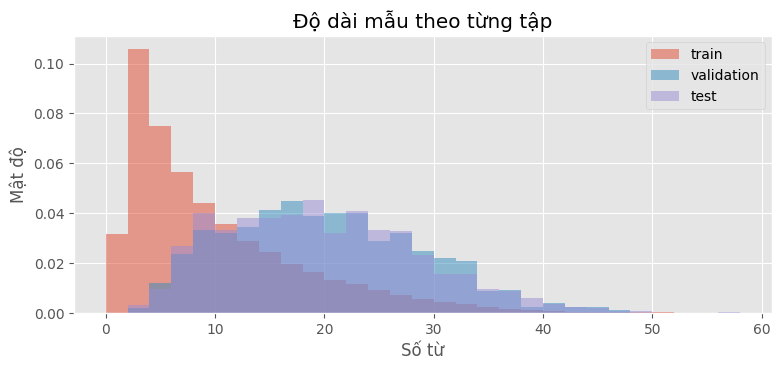

Vài mẫu train:
  - with outtakes in which most of the characters forget their lines and just utter ` uhhh , ' which is better than most of the writing in the movie 
  - enigma is well-made 
  - is ) so stoked to make an important film about human infidelity and happenstance that he tosses a kitchen sink onto a story already overladen with plot conceits . 
  - the closest thing to the experience of space travel 
  - lose their luster 
  - reopens an interesting controversy and 


In [6]:
for df in data.values():
    df['n_words'] = df['text'].str.split().str.len()

print(pd.DataFrame({k: df['n_words'].describe() for k, df in data.items()}).round(1).T)

fig, ax = plt.subplots(figsize=(9, 3.6))
bins = np.arange(0, 60, 2)
for split, df in data.items():
    ax.hist(df['n_words'], bins=bins, density=True, alpha=0.5, label=split)
ax.set_xlabel('Số từ')
ax.set_ylabel('Mật độ')
ax.set_title('Độ dài mẫu theo từng tập')
ax.legend()
plt.show()

print('Vài mẫu train:')
for text in train_df['text'].sample(6, random_state=SEED):
    print('  -', text)

### 3.3. Chất lượng dữ liệu: trùng lặp và rò rỉ

Kiểm tra số mẫu train trùng nhau, số khoá chuẩn hoá (hàm `match_key`, bỏ qua dấu câu) mang hai nhãn khác nhau và số câu đánh giá trùng khoá chuẩn hoá với train.
Nếu tỉ lệ rò rỉ lớn, điểm đánh giá sẽ không còn đo khả năng tổng quát hoá.

In [7]:
train_keys = train_df['text'].map(match_key)
print(f'Mẫu train trùng văn bản        : {len(train_df) - train_df["text"].nunique()}')
print(f'Khoá chuẩn hoá train có 2 nhãn   : {(train_df.groupby(train_keys)["label"].nunique() > 1).sum()}')
for split, keys in [('validation', dev_keys), ('test', test_keys)]:
    print(f'Câu {split:10s} trùng khoá chuẩn hoá với train: {keys.isin(set(train_keys)).sum()}')

for token in ["n't", ' , ', '``']:
    share = train_df['text'].str.contains(token, regex=False).mean()
    print(f'Tỉ lệ mẫu train chứa {token!r:8s}: {100 * share:.1f}%')

Mẫu train trùng văn bản        : 371
Khoá chuẩn hoá train có 2 nhãn   : 157
Câu validation trùng khoá chuẩn hoá với train: 2
Câu test       trùng khoá chuẩn hoá với train: 6
Tỉ lệ mẫu train chứa "n't"   : 3.3%
Tỉ lệ mẫu train chứa ' , '   : 25.0%
Tỉ lệ mẫu train chứa '``'    : 1.1%


Ba nhóm mẫu này đều rất nhỏ so với kích thước tập dữ liệu, nên được giữ nguyên để bám sát bộ dữ liệu chuẩn.

Văn bản SST đã được **tách từ sẵn và viết thường**: *"does n't"* là hai token và dấu câu đứng tách rời.
Hệ quả với baseline: mẫu token mặc định của `TfidfVectorizer` (`\b\w\w+\b`) **làm mất** `n't` và cả dấu câu.
Mục 4 thử cả mẫu `\S+` để xem việc giữ lại các token này có giúp ích không.

### 3.4. Từ phân biệt hai nhãn

Log-odds ratio: dương là nghiêng về `positive`, âm là nghiêng về `negative`. Chỉ xét từ xuất hiện ít nhất 100 lần.

In [8]:
count_vec = CountVectorizer(token_pattern=r'\S+')
counts = count_vec.fit_transform(train_df['text'])
vocab = np.array(count_vec.get_feature_names_out())
freq_neg = np.asarray(counts[(train_df['label'] == 0).values].sum(axis=0)).ravel()
freq_pos = np.asarray(counts[(train_df['label'] == 1).values].sum(axis=0)).ravel()

log_odds = np.log((freq_pos + 1) / freq_pos.sum()) - np.log((freq_neg + 1) / freq_neg.sum())
frequent = (freq_neg + freq_pos) >= 100
order = np.argsort(log_odds[frequent])
print('Nghiêng về negative:', ', '.join(vocab[frequent][order[:15]]))
print('Nghiêng về positive:', ', '.join(vocab[frequent][order[::-1][:15]]))

Nghiêng về negative: unfunny, worse, flat, stupid, ugly, pretentious, shallow, worst, mess, contrived, tired, tedious, waste, bad, dull
Nghiêng về positive: touching, perfectly, unique, solid, terrific, powerful, portrait, hilarious, inventive, beautifully, engrossing, remarkable, moving, wonderful, excellent


## 4. Baseline: TF-IDF + Logistic Regression

**TF-IDF** biểu diễn mỗi câu bằng một vector thưa theo từ và cụm từ, giảm trọng số của từ xuất hiện ở khắp nơi:

$$\text{tfidf}(t, d) = (1 + \log \text{tf}(t, d)) \times \left(\log\frac{1 + N}{1 + \text{df}(t)} + 1\right)$$

**Logistic Regression** học một trọng số cho mỗi đặc trưng: $P(\text{positive} \mid d) = \sigma(\mathbf{w}^\top \mathbf{x}_d + b)$.
`C` là nghịch đảo độ mạnh điều chuẩn L2.

Công thức trên ứng với `sublinear_tf=True`; vector được chuẩn hoá L2, và hai thiết lập này cố định, không dò. Không có tiền xử lý thêm: cả hai mô hình nhận cùng văn bản của GLUE. Siêu tham số được dò bằng `PredefinedSplit`
(học trên train, chấm trên validation):

| Tham số | Giá trị thử |
|---|---|
| `token_pattern` | mặc định `\b\w\w+\b`, hoặc `\S+` (giữ `n't` và dấu câu) |
| `ngram_range` | `(1,1)`, `(1,2)`, `(1,3)` |
| `C` | 0.5, 1, 2, 4, 8, 16, 32 |

In [9]:
baseline = Pipeline([
    ('tfidf', TfidfVectorizer(sublinear_tf=True)),
    ('clf', LogisticRegression(max_iter=2000, solver='liblinear')),
])
param_grid = {
    'tfidf__token_pattern': [r'(?u)\b\w\w+\b', r'\S+'],
    'tfidf__ngram_range': [(1, 1), (1, 2), (1, 3)],
    'clf__C': [0.5, 1, 2, 4, 8, 16, 32],
}
X_search = pd.concat([train_df['text'], dev_df['text']], ignore_index=True)
y_search = pd.concat([train_df['label'], dev_df['label']], ignore_index=True)
split = PredefinedSplit([-1] * len(train_df) + [0] * len(dev_df))

search = GridSearchCV(baseline, param_grid, cv=split, scoring='accuracy', n_jobs=-1, refit=False)
search.fit(X_search, y_search)
print('Tham số tốt nhất :', search.best_params_)
print('Accuracy validation:', round(search.best_score_, 4))

grid = pd.DataFrame(search.cv_results_['params'])
grid['accuracy'] = search.cv_results_['mean_test_score']
grid['cấu hình'] = grid['tfidf__token_pattern'].map({r'(?u)\b\w\w+\b': 'mặc định', r'\S+': r'\S+'}) + ' ' + grid['tfidf__ngram_range'].astype(str)
grid.pivot(index='cấu hình', columns='clf__C', values='accuracy').round(4)

Tham số tốt nhất : {'clf__C': 32, 'tfidf__ngram_range': (1, 3), 'tfidf__token_pattern': '(?u)\\b\\w\\w+\\b'}
Accuracy validation: 0.8326


clf__C,0.5,1.0,2.0,4.0,8.0,16.0,32.0
cấu hình,,,,,,,
"\S+ (1, 1)",0.8108,0.8154,0.8177,0.8119,0.8165,0.8142,0.8085
"\S+ (1, 2)",0.8028,0.8050,0.8073,0.8085,0.8154,0.8211,0.8200
"\S+ (1, 3)",0.7993,0.8085,0.8142,0.8142,0.8211,0.8280,0.8245
"mặc định (1, 1)",0.8165,0.8245,0.8188,0.8211,0.8188,0.8119,0.8096
"mặc định (1, 2)",0.8096,0.8039,0.8165,0.8211,0.8268,0.8257,0.8245
"mặc định (1, 3)",0.8062,0.8050,0.8119,0.8200,0.8200,0.8257,0.8326


**Nhận xét.** Tổ hợp tốt nhất đạt 83,26% trên validation với `C = 32`, n-gram `(1,3)` và mẫu token mặc định. Các tổ hợp tốt đều nằm trong khoảng 82–83%,
tức chênh nhau tối đa khoảng 11 câu trên 872 câu, nên thứ hạng giữa chúng phần lớn là nhiễu. Cụ thể, `\S+` tốt nhất đạt 82,80%, nghĩa là giữ `n't`
và dấu câu **không** tạo ra cải thiện rõ rệt. `C = 32` nằm ở biên lưới, nhưng kiểm tra riêng cho thấy `C = 64` giữ nguyên 83,26%
còn `C = 128` và `256` giảm xuống 82,91% và 82,34%, nên mở rộng lưới không giúp baseline tốt hơn.

Huấn luyện lại baseline với tham số tốt nhất **chỉ trên train** (giống BERT), đo thời gian rồi đánh giá. `report` in cả bốn độ đo
và kết quả cho từng lớp.

In [10]:
def compute_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='binary', pos_label=1, zero_division=0)
    return {'accuracy': accuracy_score(y_true, y_pred), 'precision': precision, 'recall': recall, 'f1': f1}


def report(name, y_true, y_pred):
    metrics = compute_metrics(y_true, y_pred)
    print(f'[{name}]  ' + '  '.join(f'{k} = {v:.4f}' for k, v in metrics.items()))
    print(classification_report(y_true, y_pred, target_names=LABEL_NAMES, digits=4))
    return metrics


baseline.set_params(**search.best_params_)
start = time.perf_counter()
baseline.fit(train_df['text'], train_df['label'])
lr_train_time = time.perf_counter() - start

y_dev, y_test = dev_df['label'].values, test_df['label'].values
lr_dev_pred = baseline.predict(dev_df['text'])
start = time.perf_counter()
lr_test_proba = baseline.predict_proba(test_df['text'])[:, 1]
lr_infer_time = time.perf_counter() - start
lr_test_pred = (lr_test_proba >= 0.5).astype(int)

n_features = len(baseline.named_steps['tfidf'].vocabulary_)
print(f'Số đặc trưng: {n_features:,}; huấn luyện {lr_train_time:.1f} giây; dự đoán test {lr_infer_time:.2f} giây\n')

results = {'validation': {}, 'test': {}}
results['validation']['TF-IDF + LR'] = report('TF-IDF + LR / validation', y_dev, lr_dev_pred)
results['test']['TF-IDF + LR'] = report('TF-IDF + LR / test', y_test, lr_test_pred)

Số đặc trưng: 171,469; huấn luyện 2.8 giây; dự đoán test 0.10 giây

[TF-IDF + LR / validation]  accuracy = 0.8326  precision = 0.8130  recall = 0.8716  f1 = 0.8413
              precision    recall  f1-score   support

    negative     0.8561    0.7921    0.8228       428
    positive     0.8130    0.8716    0.8413       444

    accuracy                         0.8326       872
   macro avg     0.8345    0.8318    0.8321       872
weighted avg     0.8341    0.8326    0.8322       872

[TF-IDF + LR / test]  accuracy = 0.8232  precision = 0.7968  recall = 0.8669  f1 = 0.8303
              precision    recall  f1-score   support

    negative     0.8546    0.7796    0.8154       912
    positive     0.7968    0.8669    0.8303       909

    accuracy                         0.8232      1821
   macro avg     0.8257    0.8232    0.8229      1821
weighted avg     0.8257    0.8232    0.8228      1821



### Baseline đã học được gì?

Mỗi đặc trưng có một trọng số, nên mô hình có thể đọc trực tiếp. Bảng dưới là 15 đặc trưng mạnh nhất mỗi phía,
tiếp theo là trọng số của một số cụm phủ định.

In [11]:
feature_names = baseline.named_steps['tfidf'].get_feature_names_out()
coefs = baseline.named_steps['clf'].coef_.ravel()
order = np.argsort(coefs)
print(f"{'Ủng hộ NEGATIVE':30s} Ủng hộ POSITIVE")
for neg_i, pos_i in zip(order[:15], order[::-1][:15]):
    print(f'{coefs[neg_i]:7.2f}  {feature_names[neg_i]:20s} {coefs[pos_i]:7.2f}  {feature_names[pos_i]}')

print()
index = baseline.named_steps['tfidf'].vocabulary_
for phrase in ['good', 'not good', 'bad', 'not bad', 'funny', 'not funny', "n't", "does n't work"]:
    print(f'{phrase:15s}', f'{coefs[index[phrase]]:7.2f}' if phrase in index else '  (không có trong từ điển)')

Ủng hộ NEGATIVE                Ủng hộ POSITIVE
 -16.13  lacks                  14.80  good
 -15.69  too                    13.26  fascinating
 -15.18  bad                    12.26  beautiful
 -13.14  lacking                12.21  best
 -12.06  worst                  12.11  powerful
 -11.43  less                   11.87  entertaining
 -11.26  neither                11.24  never dull
 -11.24  nothing                11.09  fun
 -11.00  mess                   11.00  compelling
 -10.49  low                    10.86  hilarious
 -10.46  stupid                 10.82  love
 -10.46  lack                   10.77  enjoyable
 -10.40  fails                  10.66  not bad
 -10.28  dull                   10.65  funny
 -10.04  failure                10.39  well

good              14.80
not good          -6.70
bad              -15.18
not bad           10.66
funny             10.65
not funny         -5.00
n't               (không có trong từ điển)
does n't work     (không có trong từ điển)


## 5. Fine-tune BERT

BERT là Transformer encoder (12 lớp, 768 chiều, ~110 triệu tham số) đã được tiền huấn luyện trên lượng lớn văn bản.
Fine-tuning thêm một lớp tuyến tính 768 → 2 lên đầu ra pooler (vector `[CLS]` qua một lớp dense + tanh), rồi huấn luyện toàn bộ mạng với learning rate nhỏ trong vài epoch.

### 5.1. Cấu hình

| Tham số | Giá trị | Lý do |
|---|---|---|
| `MODEL_NAME` | `bert-base-uncased` | Dữ liệu đã viết thường |
| `MAX_LEN` | `128` | Câu dài nhất SST-2 chỉ khoảng 66 token (đo ở mục 5.2), nên không câu nào bị cắt |
| `BATCH_SIZE` | `32` | Khuyến nghị của Devlin và cộng sự (16 hoặc 32) |
| `EPOCHS` | `3` | Trong khoảng 2–4 được khuyến nghị; epoch tốt nhất được chọn theo validation |
| `LEARNING_RATE` | `2e-5` | Khuyến nghị 2e-5 đến 5e-5 |
| `WARMUP_RATIO` | `0.1` | Tăng dần learning rate trong 10% số bước đầu rồi giảm tuyến tính về 0 |
| `WEIGHT_DECAY` | `0.01` | Không áp cho bias và LayerNorm |
| `N_TRAIN` | `None` | Đặt số nhỏ, ví dụ `2000`, để chạy thử nhanh |

In [ ]:
MODEL_NAME = 'bert-base-uncased'
MAX_LEN = 128
BATCH_SIZE = 32
EPOCHS = 3
LEARNING_RATE = 2e-5
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
N_TRAIN = None      # ví dụ 2000 để chạy thử; None = toàn bộ train

USE_AMP = device.type == 'cuda'   # mixed precision chỉ bật trên GPU NVIDIA


def autocast():
    return torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP)

### 5.2. Tokenizer

WordPiece tách từ hiếm thành các mảnh có tiền tố `##`, đồng thời thêm `[CLS]` và `[SEP]`. Lưu ý *"does n't"* trong SST bị tách thành
`does`, `n`, `'`, `t`. Đoạn mã dưới cũng đo độ dài token để xác nhận `MAX_LEN` không cắt mất câu nào.

In [13]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(tokenizer.convert_ids_to_tokens(tokenizer("it does n't work , but the cinematography is breathtaking .")['input_ids']))

for split, df in data.items():
    lengths = np.array([len(ids) for ids in tokenizer(df['text'].tolist())['input_ids']])
    print(f'{split:10s}: trung vị {np.median(lengths):4.0f}, phân vị 99 {np.percentile(lengths, 99):5.1f}, '
          f'lớn nhất {lengths.max():3d}, bị cắt {(lengths > MAX_LEN).sum()}')

['[CLS]', 'it', 'does', 'n', "'", 't', 'work', ',', 'but', 'the', 'cinematography', 'is', 'breath', '##taking', '.', '[SEP]']
train     : trung vị   10, phân vị 99  44.0, lớn nhất  66, bị cắt 0
validation: trung vị   24, phân vị 99  51.3, lớn nhất  55, bị cắt 0
test      : trung vị   24, phân vị 99  53.8, lớn nhất  64, bị cắt 0


### 5.3. Chuẩn bị dữ liệu

Tokenize theo lô, chưa đệm. `DataCollatorWithPadding` đệm theo câu dài nhất **trong mỗi lô**, giúp tiết kiệm đáng kể vì phần lớn mẫu train rất ngắn.

In [14]:
def to_loader(df, shuffle=False, n=None):
    if n is not None:
        df = df.sample(n=min(n, len(df)), random_state=SEED)
    ds = datasets.Dataset.from_pandas(df[['text', 'label']].reset_index(drop=True), preserve_index=False)
    ds = ds.map(lambda b: tokenizer(b['text'], truncation=True, max_length=MAX_LEN), batched=True, remove_columns=['text'])
    ds = ds.rename_column('label', 'labels')
    generator = torch.Generator().manual_seed(SEED) if shuffle else None
    return DataLoader(ds, batch_size=BATCH_SIZE if shuffle else BATCH_SIZE * 2, shuffle=shuffle,
                      collate_fn=DataCollatorWithPadding(tokenizer), generator=generator)


train_loader = to_loader(train_df, shuffle=True, n=N_TRAIN)
dev_loader = to_loader(dev_df)
test_loader = to_loader(test_df)

batch = next(iter(train_loader))
print({k: tuple(v.shape) for k, v in batch.items()})
print('Số lô train mỗi epoch:', len(train_loader))

{'labels': (32,), 'input_ids': (32, 33), 'token_type_ids': (32, 33), 'attention_mask': (32, 33)}
Số lô train mỗi epoch: 2105


### 5.4. Mô hình, optimizer và lịch learning rate

In [15]:
set_seed()
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=2,
    id2label=dict(enumerate(LABEL_NAMES)), label2id={name: i for i, name in enumerate(LABEL_NAMES)},
).to(device)
n_params = sum(p.numel() for p in model.parameters())

no_decay = ('bias', 'LayerNorm.weight')
optimizer = torch.optim.AdamW([
    {'params': [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], 'weight_decay': WEIGHT_DECAY},
    {'params': [p for n, p in model.named_parameters() if any(k in n for k in no_decay)], 'weight_decay': 0.0},
], lr=LEARNING_RATE)

num_steps = EPOCHS * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * num_steps), num_steps)
scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)
print(f'{n_params / 1e6:.1f} triệu tham số; {num_steps} bước huấn luyện')

109.5 triệu tham số; 6315 bước huấn luyện


### 5.5. Huấn luyện

Mỗi bước gồm lan truyền xuôi, lan truyền ngược, cắt gradient ở chuẩn 1.0 rồi cập nhật trọng số. Cuối mỗi epoch, mô hình được chấm trên
validation và trọng số của epoch có accuracy cao nhất được giữ lại. **Tập test không tham gia vào quyết định này.**

In [16]:
@torch.no_grad()
def predict_proba(loader):
    model.eval()
    probs = []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items() if k != 'labels'}
        with autocast():
            logits = model(**batch).logits
        probs.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu())
    return torch.cat(probs).numpy()


LOG_EVERY = 500
losses, dev_history = [], []
best_dev_acc, best_state, best_epoch = -1.0, None, None

set_seed()
start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    for batch in train_loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with autocast():
            loss = model(**batch).loss
        optimizer.zero_grad()
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()

        losses.append(loss.item())
        if len(losses) % LOG_EVERY == 0:
            print(f'bước {len(losses):5d}/{num_steps}  loss TB {np.mean(losses[-LOG_EVERY:]):.4f}  '
                  f'{(time.perf_counter() - start) / 60:5.1f} phút', flush=True)

    dev_metrics = compute_metrics(y_dev, (predict_proba(dev_loader) >= 0.5).astype(int))
    dev_history.append(dev_metrics)
    print(f'epoch {epoch}: ' + '  '.join(f'{k} = {v:.4f}' for k, v in dev_metrics.items()), flush=True)
    if dev_metrics['accuracy'] > best_dev_acc:
        best_dev_acc, best_epoch = dev_metrics['accuracy'], epoch
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

bert_train_time = time.perf_counter() - start
model.load_state_dict(best_state)
print(f'\nHuấn luyện {bert_train_time / 60:.1f} phút; chọn epoch {best_epoch} (accuracy validation = {best_dev_acc:.4f})')

bước   500/6315  loss TB 0.4191    0.8 phút
bước  1000/6315  loss TB 0.2327    1.7 phút
bước  1500/6315  loss TB 0.1918    2.5 phút
bước  2000/6315  loss TB 0.1784    3.4 phút
epoch 1: accuracy = 0.9174  precision = 0.9387  recall = 0.8964  f1 = 0.9171
bước  2500/6315  loss TB 0.1228    4.2 phút
bước  3000/6315  loss TB 0.1190    5.1 phút
bước  3500/6315  loss TB 0.1168    5.9 phút
bước  4000/6315  loss TB 0.1086    6.8 phút
epoch 2: accuracy = 0.9220  precision = 0.9372  recall = 0.9077  f1 = 0.9222
bước  4500/6315  loss TB 0.0858    7.6 phút
bước  5000/6315  loss TB 0.0756    8.5 phút
bước  5500/6315  loss TB 0.0763    9.3 phút
bước  6000/6315  loss TB 0.0698   10.1 phút
epoch 3: accuracy = 0.9266  precision = 0.9279  recall = 0.9279  f1 = 0.9279

Huấn luyện 10.7 phút; chọn epoch 3 (accuracy validation = 0.9266)


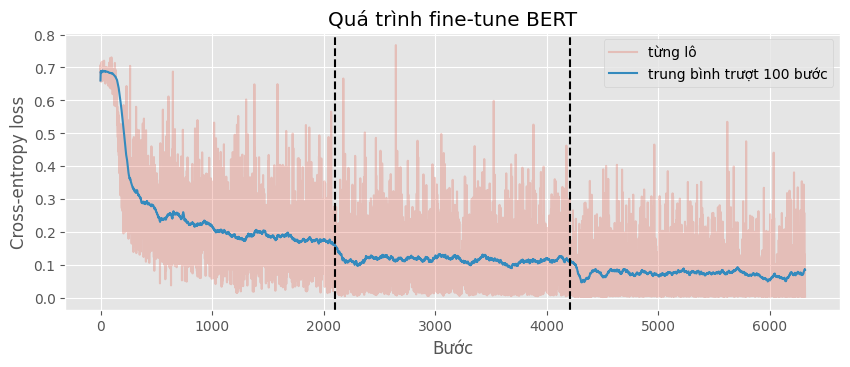

,accuracy,precision,recall,f1
epoch,,,,
1,0.9174,0.9387,0.8964,0.9171
2,0.9220,0.9372,0.9077,0.9222
3,0.9266,0.9279,0.9279,0.9279


In [17]:
loss_series = pd.Series(losses)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(loss_series, alpha=0.25, label='từng lô')
ax.plot(loss_series.rolling(100, min_periods=1).mean(), label='trung bình trượt 100 bước')
for e in range(1, EPOCHS):
    ax.axvline(e * len(train_loader), color='black', linestyle='--')
ax.set_xlabel('Bước')
ax.set_ylabel('Cross-entropy loss')
ax.set_title('Quá trình fine-tune BERT')
ax.legend()
plt.show()

pd.DataFrame(dev_history, index=pd.Index(range(1, EPOCHS + 1), name='epoch')).round(4)

**Nhận xét.** Accuracy validation tăng nhẹ qua từng epoch (91,74% → 92,20% → 92,66%), trong khi loss train giảm từ khoảng 0,18 xuống 0,07.
Mức tăng giữa các epoch chỉ tương đương 4 câu trên 872 câu, nên chọn epoch 3 không chắc chắn hơn nhiều so với epoch 2. Không thấy dấu hiệu validation giảm
do quá khớp trong 3 epoch này.

Có thể lưu mô hình để dùng lại (khoảng 440 MB, không đưa lên GitHub) bằng cách bỏ dấu `#`:

In [ ]:
# model.save_pretrained('data/bert-sst2'); tokenizer.save_pretrained('data/bert-sst2')

## 6. Đánh giá BERT

Trong lần chạy này, mô hình đã chốt được chấm một lần trên validation và một lần trên test.

In [19]:
bert_dev_proba = predict_proba(dev_loader)
start = time.perf_counter()
bert_test_proba = predict_proba(test_loader)
bert_infer_time = time.perf_counter() - start
bert_test_pred = (bert_test_proba >= 0.5).astype(int)

results['validation']['BERT'] = report('BERT / validation', y_dev, (bert_dev_proba >= 0.5).astype(int))
results['test']['BERT'] = report('BERT / test', y_test, bert_test_pred)
print(f'Dự đoán {len(y_test):,} câu test: {bert_infer_time:.1f} giây')

[BERT / validation]  accuracy = 0.9266  precision = 0.9279  recall = 0.9279  f1 = 0.9279
              precision    recall  f1-score   support

    negative     0.9252    0.9252    0.9252       428
    positive     0.9279    0.9279    0.9279       444

    accuracy                         0.9266       872
   macro avg     0.9266    0.9266    0.9266       872
weighted avg     0.9266    0.9266    0.9266       872

[BERT / test]  accuracy = 0.9396  precision = 0.9210  recall = 0.9615  f1 = 0.9408
              precision    recall  f1-score   support

    negative     0.9599    0.9178    0.9383       912
    positive     0.9210    0.9615    0.9408       909

    accuracy                         0.9396      1821
   macro avg     0.9404    0.9396    0.9396      1821
weighted avg     0.9404    0.9396    0.9396      1821

Dự đoán 1,821 câu test: 1.4 giây


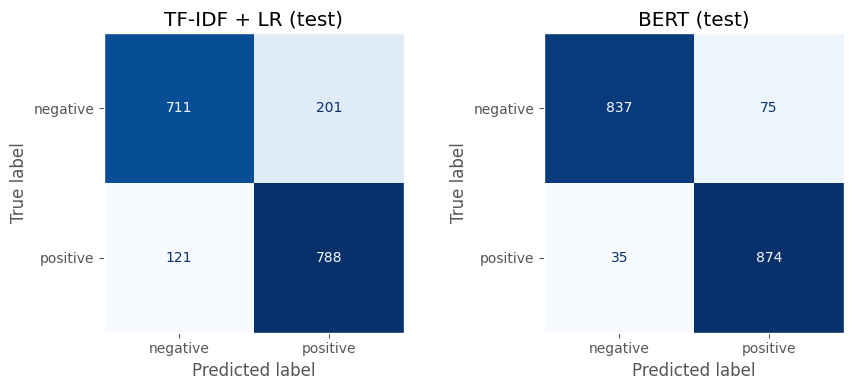

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, pred, title in zip(axes, [lr_test_pred, bert_test_pred], ['TF-IDF + LR (test)', 'BERT (test)']):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=LABEL_NAMES).plot(
        ax=ax, cmap='Blues', values_format='d', colorbar=False)
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()
plt.show()

## 7. So sánh hai mô hình

### 7.1. Bảng tổng hợp

accuracy  precision  recall      f1
tập        mô hình                                         
validation TF-IDF + LR    0.8326     0.8130  0.8716  0.8413
           BERT           0.9266     0.9279  0.9279  0.9279
test       TF-IDF + LR    0.8232     0.7968  0.8669  0.8303
           BERT           0.9396     0.9210  0.9615  0.9408

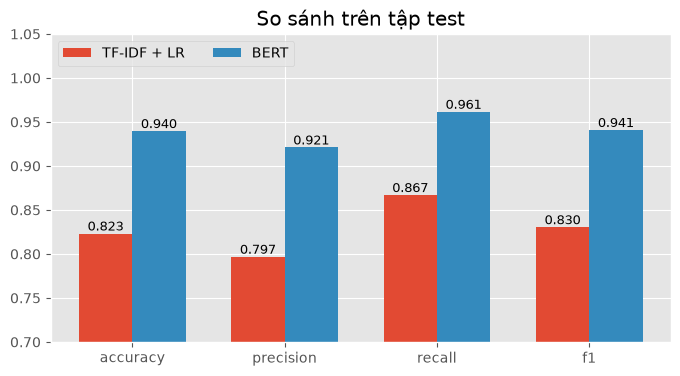

,Thời gian huấn luyện (giây),Dự đoán test (giây),Số tham số
TF-IDF + LR,2.8,0.1,"171,470"
BERT (cuda),641.3,1.4,"109,483,778"


In [21]:
comparison = pd.concat({split: pd.DataFrame(values).T for split, values in results.items()}, names=['tập', 'mô hình'])
display(comparison.round(4))

metric_names = ['accuracy', 'precision', 'recall', 'f1']
fig, ax = plt.subplots(figsize=(8, 4))
width = 0.35
for k, (name, metrics) in enumerate(results['test'].items()):
    bars = ax.bar(np.arange(4) + k * width, [metrics[m] for m in metric_names], width, label=name)
    ax.bar_label(bars, fmt='%.3f', fontsize=9)
ax.set_xticks(np.arange(4) + width / 2, metric_names)
ax.set_ylim(0.7, 1.05)
ax.set_title('So sánh trên tập test')
ax.legend(loc='upper left', ncols=2)
plt.show()

pd.DataFrame({
    'Thời gian huấn luyện (giây)': [lr_train_time, bert_train_time],
    'Dự đoán test (giây)': [lr_infer_time, bert_infer_time],
    'Số tham số': [n_features + 1, n_params],
}, index=['TF-IDF + LR', f'BERT ({device.type})']).style.format('{:,.1f}').format('{:,.0f}', subset=['Số tham số'])

### 7.2. Khoảng tin cậy bootstrap

Tập test chỉ có 1.821 câu nên sai số đáng kể. Lấy mẫu lại có hoàn lại 5.000 lần, **dùng cùng các chỉ số mẫu cho cả hai mô hình**
(bootstrap ghép cặp), rồi lấy phân vị 2,5% và 97,5%. Mỗi ô của bảng ghi trung bình bootstrap [phân vị 2,5%, phân vị 97,5%], nên số đầu có thể lệch nhẹ so với giá trị đo trực tiếp. Nếu khoảng của phần chênh lệch không chứa 0, chênh lệch đáng tin cậy ở mức 95%.

In [22]:
rng = np.random.default_rng(SEED)
boot_idx = rng.integers(0, len(y_test), size=(5000, len(y_test)))
boot = {name: np.array([list(compute_metrics(y_test[i], pred[i]).values()) for i in boot_idx])
        for name, pred in {'TF-IDF + LR': lr_test_pred, 'BERT': bert_test_pred}.items()}
boot['BERT − LR'] = boot['BERT'] - boot['TF-IDF + LR']

ci = pd.DataFrame({name: [f'{values[:, j].mean():+.4f} [{np.percentile(values[:, j], 2.5):+.4f}, {np.percentile(values[:, j], 97.5):+.4f}]'
                          for j in range(4)] for name, values in boot.items()}, index=metric_names)
ci

,TF-IDF + LR,BERT,BERT − LR
accuracy,"+0.8232 [+0.8051, +0.8413]","+0.9395 [+0.9286, +0.9506]","+0.1163 [+0.0977, +0.1351]"
precision,"+0.7968 [+0.7722, +0.8211]","+0.9208 [+0.9036, +0.9376]","+0.1240 [+0.1003, +0.1480]"
recall,"+0.8667 [+0.8443, +0.8888]","+0.9614 [+0.9485, +0.9733]","+0.0947 [+0.0723, +0.1171]"
f1,"+0.8303 [+0.8113, +0.8487]","+0.9407 [+0.9296, +0.9518]","+0.1104 [+0.0926, +0.1288]"


### 7.3. Kiểm định McNemar

Hai mô hình chấm trên cùng các câu nên kết quả không độc lập. McNemar chỉ xét các câu hai mô hình bất đồng:
$b$ là số câu chỉ baseline đúng, $c$ là số câu chỉ BERT đúng. Giả thuyết $H_0$ là mỗi câu bất đồng có xác suất 50/50 thuộc về $b$ hay $c$,
kiểm tra bằng kiểm định nhị thức chính xác.

In [23]:
compare_df = test_df[['text', 'label', 'n_words']].copy()
compare_df['lr_proba'], compare_df['bert_proba'] = lr_test_proba, bert_test_proba
compare_df['lr_pred'], compare_df['bert_pred'] = lr_test_pred, bert_test_pred
compare_df['lr_ok'] = compare_df['lr_pred'] == compare_df['label']
compare_df['bert_ok'] = compare_df['bert_pred'] == compare_df['label']

print(pd.crosstab(compare_df['lr_ok'].map({True: 'LR đúng', False: 'LR sai'}),
                  compare_df['bert_ok'].map({True: 'BERT đúng', False: 'BERT sai'})), '\n')
b = int((compare_df['lr_ok'] & ~compare_df['bert_ok']).sum())
c = int((~compare_df['lr_ok'] & compare_df['bert_ok']).sum())
print(f'b = {b}, c = {c}, McNemar exact p-value = {scipy.stats.binomtest(b, b + c, p=0.5).pvalue:.2e}')

bert_ok  BERT sai  BERT đúng
lr_ok                       
LR sai         59        263
LR đúng        51       1448 

b = 51, c = 263, McNemar exact p-value = 1.43e-35


### 7.4. Theo độ dài câu và hiện tượng ngôn ngữ

Giả thuyết: túi từ yếu hơn ở câu có **phủ định** và **tương phản**, vì nghĩa phụ thuộc vào cấu trúc chứ không chỉ các từ riêng lẻ.
Các nhóm được xác định bằng danh sách từ khoá đơn giản, nên đây là phân tích mô tả, không phải kiểm định chặt chẽ.

In [24]:
def group_accuracy(mask):
    subset = compare_df[mask]
    return {'n': len(subset), 'LR': subset['lr_ok'].mean(), 'BERT': subset['bert_ok'].mean(),
            'BERT − LR': subset['bert_ok'].mean() - subset['lr_ok'].mean()}


tokens = compare_df['text'].str.split().map(set)
NEGATION = {'not', "n't", 'no', 'never', 'nothing', 'neither', 'nor', 'without', 'hardly', 'barely'}
CONTRAST = {'but', 'however', 'yet', 'though', 'although', 'despite', 'while'}
has_neg, has_con = tokens.map(lambda t: bool(t & NEGATION)), tokens.map(lambda t: bool(t & CONTRAST))

length_bucket = pd.qcut(compare_df['n_words'], q=4)
groups = {f'{int(iv.left) + 1}–{int(iv.right)} từ': length_bucket == iv for iv in length_bucket.cat.categories}
groups.update({'có phủ định': has_neg, 'có tương phản': has_con, 'không có cả hai': ~has_neg & ~has_con})
pd.DataFrame({name: group_accuracy(mask) for name, mask in groups.items()}).T.astype({'n': int}).round(4)

,n,LR,BERT,BERT − LR
2–12 từ,476,0.8445,0.9349,0.0903
13–18 từ,441,0.8458,0.9637,0.1179
19–25 từ,464,0.8297,0.9353,0.1056
26–56 từ,440,0.7705,0.9250,0.1545
có phủ định,366,0.7623,0.9399,0.1776
có tương phản,337,0.7389,0.9407,0.2018
không có cả hai,1230,0.8496,0.9407,0.0911


**Nhận xét.** Baseline giảm rõ ở câu có phủ định (76,2%), có tương phản (73,9%) và câu dài nhất (77,0%), còn BERT giữ được 92,5–94,1% ở các nhóm này; riêng phủ định, tương phản và nhóm không có cả hai gần như không đổi (94,0%, 94,1%, 94,1%), nên khoảng cách tăng hoàn toàn do baseline giảm.
Vì vậy khoảng cách giữa hai mô hình lớn nhất ở phủ định (+17,8 điểm) và tương phản (+20,2 điểm), so với +9,1 điểm ở nhóm không có hai hiện tượng này —
**phù hợp với giả thuyết** về điểm yếu của túi từ. Hai nhóm phủ định và tương phản chồng lấn 112 câu, và mỗi nhóm chỉ có vài trăm câu, nên chênh lệch của từng hiện tượng riêng lẻ có thể nhỏ hơn. Ngoài ra baseline được chọn dùng mẫu token mặc định nên mất `n't` (mục 4), vì vậy một phần khoảng cách ở nhóm phủ định có thể đến từ cách tách token; nhóm tương phản không chịu ảnh hưởng này. Do đó đây là bằng chứng mô tả chứ chưa phải quan hệ nhân quả.

### 7.5. Các câu hai mô hình bất đồng

Lấy những câu ngắn để dễ đọc, kèm $P(\text{positive})$ của từng mô hình.

In [25]:
def show_examples(mask, title, n=6):
    print(f'===== {title} =====')
    for _, row in compare_df[mask].sort_values('n_words').head(n).iterrows():
        print(f"[{LABEL_NAMES[row['label']]}]  LR = {row['lr_proba']:.2f}, BERT = {row['bert_proba']:.2f}  {row['text']}")
    print()


show_examples(~compare_df['lr_ok'] & compare_df['bert_ok'], 'Chỉ BERT đúng')
show_examples(compare_df['lr_ok'] & ~compare_df['bert_ok'], 'Chỉ baseline đúng')

===== Chỉ BERT đúng =====
[negative]  LR = 0.73, BERT = 0.02  moot point .
[negative]  LR = 0.76, BERT = 0.00  a real clunker .
[negative]  LR = 0.71, BERT = 0.00  it 's also stupider .
[negative]  LR = 1.00, BERT = 0.04  first good , then bothersome .
[negative]  LR = 0.57, BERT = 0.01  showtime is closer to slowtime .
[negative]  LR = 0.89, BERT = 0.33  like a south-of-the-border melrose place .

===== Chỉ baseline đúng =====
[negative]  LR = 0.23, BERT = 0.99  is this progress ?
[positive]  LR = 0.84, BERT = 0.02  much monkeyfun for all .
[negative]  LR = 0.00, BERT = 0.98  do n't waste your money .
[negative]  LR = 0.30, BERT = 0.97  sushi for the connoisseurs of the macabre .
[positive]  LR = 0.98, BERT = 0.26  message movie or an action-packed submarine spectacular ?
[negative]  LR = 0.04, BERT = 0.75  the movie bounces all over the map .



## 8. Phân tích lỗi của BERT

Những lỗi có độ tin cậy cao nhất cho biết câu thực sự khó hay nhãn có vấn đề. Bảng theo mức độ tin cậy tiếp theo kiểm tra xem xác suất
của mô hình có phản ánh đúng khả năng dự đoán đúng hay không.

In [26]:
errors = compare_df[~compare_df['bert_ok']].copy()
errors['confidence'] = np.maximum(errors['bert_proba'], 1 - errors['bert_proba'])
print(f"BERT sai {len(errors)}/{len(compare_df)} câu: {(errors['label'] == 0).sum()} chê bị đoán là khen, "
      f"{(errors['label'] == 1).sum()} khen bị đoán là chê\n")
for _, row in errors.sort_values('confidence', ascending=False).head(8).iterrows():
    print(f"[thật: {LABEL_NAMES[row['label']]}, tin cậy {row['confidence']:.3f}] {row['text']}")

confidence = np.maximum(compare_df['bert_proba'], 1 - compare_df['bert_proba']).rename('confidence')
calibration = compare_df.groupby(pd.cut(confidence, [0.5, 0.7, 0.9, 0.99, 1.0], include_lowest=True), observed=True).agg(
    n=('bert_ok', 'size'), accuracy=('bert_ok', 'mean'), mean_confidence=('bert_ok', lambda s: confidence[s.index].mean()))
calibration.round(3)

BERT sai 110/1821 câu: 75 chê bị đoán là khen, 35 khen bị đoán là chê

[thật: negative, tin cậy 0.999] i weep for the future when a good portion of the respected critical community in this country consider blue crush to be an intelligent film about young women .
[thật: negative, tin cậy 0.999] a strong first quarter , slightly less so second quarter , and average second half .
[thật: negative, tin cậy 0.999] but it pays a price for its intricate intellectual gamesmanship .
[thật: negative, tin cậy 0.999] when the first few villians are introduced as `` spider '' and `` snake '' you know you 're in for a real winner , creativity at its peak .
[thật: negative, tin cậy 0.999] son of the bride may be a good half-hour too long but comes replete with a flattering sense of mystery and quietness .
[thật: negative, tin cậy 0.999] like its two predecessors , 1983 's koyaanisqatsi and 1988 's powaqqatsi , the cinematic collage naqoyqatsi could be the most navel-gazing film ever .
[thật: negative,

,n,accuracy,mean_confidence
confidence,,,
"(0.499, 0.7]",30,0.567,0.604
"(0.7, 0.9]",56,0.625,0.817
"(0.9, 0.99]",247,0.830,0.967
"(0.99, 1.0]",1488,0.977,0.998


**Nhận xét.**

- BERT sai 110/1.821 câu, thiên về đoán nhầm câu chê thành khen (75 so với 35), khớp với precision thấp hơn recall.
- Các lỗi tự tin nhất có ba dạng: **mỉa mai** (*"you 're in for a real winner , creativity at its peak"*), **từ tích cực trong ý chê**
  (*"i weep for the future when … consider blue crush to be an intelligent film about young women"*) và **nhãn đáng ngờ** (*"son of the bride may be a good half-hour too long but comes replete with a flattering sense of mystery and quietness"* lại mang nhãn `negative`).
- **BERT quá tự tin**: ở nhóm độ tin cậy 0,9–0,99, độ tin cậy trung bình là 96,7% nhưng accuracy chỉ 83,0%; nhóm 0,7–0,9 là 81,7% so với 62,5%.
  Xếp hạng vẫn hữu ích, vì nhóm trên 0,99 đạt 97,7%. Nếu cần dùng xác suất trực tiếp thì nên hiệu chỉnh, ví dụ bằng temperature scaling trên validation.

## 9. Demo

Vì SST đã được tách từ sẵn, các câu demo được viết theo cùng kiểu: chữ thường, dấu câu tách rời và *"does n't"* tách đôi.

In [27]:
@torch.no_grad()
def demo(texts):
    model.eval()
    encoded = tokenizer(texts, truncation=True, max_length=MAX_LEN, padding=True, return_tensors='pt').to(device)
    bert_p = torch.softmax(model(**encoded).logits.float(), dim=-1)[:, 1].cpu().numpy()
    lr_p = baseline.predict_proba(texts)[:, 1]
    print(f"{'LR':>5s} {'BERT':>5s}  Câu")
    for text, p1, p2 in zip(texts, lr_p, bert_p):
        print(f'{p1:5.2f} {p2:5.2f}  {text}')


demo([
    'a wonderful film , i loved every minute of it .',
    'this movie was not good at all .',
    'not bad at all , i was pleasantly surprised .',
    'i expected to hate it , but it turned out to be one of the best films of the year .',
    'great cast , beautiful scenery , and yet the most boring two hours of my life .',
    'oh great , another sequel nobody asked for .',
    "it does n't try to be clever , and it does n't need to .",
])

   LR  BERT  Câu
 1.00  1.00  a wonderful film , i loved every minute of it .
 0.02  0.00  this movie was not good at all .
 0.19  1.00  not bad at all , i was pleasantly surprised .
 0.89  1.00  i expected to hate it , but it turned out to be one of the best films of the year .
 0.98  0.69  great cast , beautiful scenery , and yet the most boring two hours of my life .
 0.48  1.00  oh great , another sequel nobody asked for .
 0.75  0.02  it does n't try to be clever , and it does n't need to .


**Nhận xét.** Đây chỉ là vài câu minh hoạ, không phải đánh giá. BERT đúng ở *"not bad at all…"*, nơi baseline sai (0,19). Tuy nhiên BERT **sai với độ tin cậy cao**
ở câu mỉa mai *"oh great , another sequel…"* (1,00). Ở câu tương phản *"great cast … yet the most boring two hours"*, BERT cũng sai nhưng ít tự tin hơn (0,69), còn baseline sai nặng hơn (0,98). Câu cuối có nghĩa tích cực nhưng BERT cho 0,02.
Như vậy, BERT tốt hơn hẳn về tổng thể nhưng chưa thực sự "hiểu" mọi cấu trúc phủ định, tương phản và mỉa mai.

## 10. Kết luận

| Tập | Mô hình | Accuracy | Precision | Recall | F1 |
|---|---|---:|---:|---:|---:|
| Validation (872 câu) | TF-IDF + LR | 0,8326 | 0,8130 | 0,8716 | 0,8413 |
| | BERT | 0,9266 | 0,9279 | 0,9279 | 0,9279 |
| **Test (1.821 câu)** | TF-IDF + LR | **0,8232** | 0,7968 | 0,8669 | 0,8303 |
| | BERT | **0,9396** | 0,9210 | 0,9615 | 0,9408 |

**BERT vượt baseline rõ rệt và đáng tin cậy về thống kê** (trên tập test này, với mô hình của lần chạy này; chưa tính dao động theo seed): trên test, accuracy cao hơn 11,6 điểm phần trăm (khoảng tin cậy 95%: 9,8–13,5 điểm) và F1 cao hơn 11,0 điểm.
Trong 314 câu hai mô hình bất đồng, BERT đúng 263 câu còn baseline đúng 51 câu (McNemar p ≈ 1,4 × 10⁻³⁵). Tham chiếu: RNTN của Socher và cộng sự (2013) đạt 85,4%
và CNN của Kim (2014), biến thể non-static và multichannel, đạt 87,2–88,1% trên SST-2 — các mốc này được công bố trong điều kiện thí nghiệm riêng, nên chỉ mang tính định hướng.

**Khoảng cách lớn hơn nhiều so với IMDb** (notebook `IMDb.ipynb`: 90,5% so với 92,4%). Một lý do hợp lý là câu SST-2 ngắn, ít từ khoá lặp lại, nên nghĩa phụ thuộc nhiều vào cấu trúc;
mục 7.4 ủng hộ cách giải thích này nhưng notebook không kiểm chứng trực tiếp. Hai thí nghiệm cũng khác nhau về độ cắt văn bản (IMDb dùng `MAX_LEN = 256`) và cấu trúc nhãn train.

**Cái giá phải trả** (BERT trên GPU của Google Colab, backend `cuda`; baseline trên CPU): BERT huấn luyện 10,7 phút và dự đoán test 1,4 giây, so với 2,8 giây và 0,10 giây của baseline. BERT cũng khó diễn giải hơn và quá tự tin ở mục 8.
Baseline vẫn hợp lý khi tài nguyên hạn chế hoặc cần giải thích trực tiếp trọng số; khi chất lượng là ưu tiên, BERT là lựa chọn rõ ràng trên bộ dữ liệu này.

### Hạn chế

1. **Tập test được khôi phục ngoài GLUE**: nhãn lấy từ `SetFit/sst2`. Việc ghép được kiểm tra chặt (mục 2.2) nhưng vẫn là bước bổ sung ngoài quy trình GLUE chính thức.
2. **Test cao hơn validation** với BERT (93,96% so với 92,66%): khoảng tin cậy của tập nhỏ như vậy đủ rộng để đây có thể chỉ là khác biệt do mẫu. Kiểm tra riêng cho thấy không có dấu hiệu rò rỉ giải thích được chênh lệch này:
   chỉ 0,7% câu test và 0,9% câu validation chứa một chuỗi từ 5 từ trở lên trùng nguyên văn một cụm từ train; nếu đếm câu có chung bất kỳ 5-gram nào với train thì là 10,4% và 13,0%, tức test vẫn thấp hơn validation.
3. **Một lần chạy, một hạt giống**: chưa đo độ dao động của BERT theo seed, và kết quả có thể lệch nhẹ giữa các môi trường: lần chạy trước trên Apple M4 cho accuracy test 93,68% so với 93,96% ở lần này (chênh 5 câu), trong khi accuracy validation vẫn 92,66%. Hai lần chạy còn khác nhau về mixed precision và phiên bản thư viện nên chưa tách được nguyên nhân.
4. **Chưa dò siêu tham số BERT**: chỉ chọn epoch, trong khi baseline được dò lưới. Điều này nếu có thì bất lợi cho BERT, nên không làm yếu kết luận.
5. **Tách từ kiểu SST**: *"does n't"* thành `does`, `n`, `'`, `t`, khác cách viết thông thường, có thể làm giảm chất lượng ở phủ định. Chưa thử khôi phục văn bản gốc.

### Hướng mở rộng

1. Chạy nhiều hạt giống và dò learning rate để đo độ ổn định.
2. Hiệu chỉnh xác suất bằng temperature scaling.
3. Khôi phục dạng viết thông thường (`does n't` → `doesn't`) trước khi tokenize.
4. So sánh với các mô hình nhẹ hơn (DistilBERT) hoặc mạnh hơn (RoBERTa, DeBERTa).

## Tài liệu tham khảo

1. Richard Socher và cộng sự (2013). *Recursive Deep Models for Semantic Compositionality Over a Sentiment Treebank.* EMNLP 2013. <https://aclanthology.org/D13-1170/>
2. Alex Wang và cộng sự (2019). *GLUE: A Multi-Task Benchmark and Analysis Platform for Natural Language Understanding.* ICLR 2019. <https://arxiv.org/abs/1804.07461>
3. Jacob Devlin, Ming-Wei Chang, Kenton Lee, Kristina Toutanova (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding.* NAACL 2019. <https://aclanthology.org/N19-1423/>
4. Yoon Kim (2014). *Convolutional Neural Networks for Sentence Classification.* EMNLP 2014. <https://aclanthology.org/D14-1181/>
5. Ilya Loshchilov, Frank Hutter (2019). *Decoupled Weight Decay Regularization.* ICLR 2019. <https://arxiv.org/abs/1711.05101>
6. Thomas G. Dietterich (1998). *Approximate Statistical Tests for Comparing Supervised Classification Learning Algorithms.* Neural Computation 10(7).
7. Fabian Pedregosa và cộng sự (2011). *Scikit-learn: Machine Learning in Python.* JMLR 12. <https://jmlr.org/papers/v12/pedregosa11a.html>
8. Hugging Face LLM Course — Chapter 3. <https://huggingface.co/learn/llm-course/chapter3>
9. Dataset cards: [`nyu-mll/glue`](https://huggingface.co/datasets/nyu-mll/glue), [`SetFit/sst2`](https://huggingface.co/datasets/SetFit/sst2)